# 06 Training and Evaluation
Input: furniture_v2_split <br>
Model: ResNet50 (ImageNet) fine-tuned for 17 classes, with augmentation and class weighting <br>
Output: trained model on Drive, validation and test results

In [ ]:
# connect Drive, restore the split dataset, check the GPU
from google.colab import drive
drive.mount('/content/drive')

import torch, numpy as np, matplotlib.pyplot as plt
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score

DRIVE = "/content/drive/MyDrive/DSGP"
!rm -rf /content/furniture_v2_split
!unzip -q -o {DRIVE}/furniture_v2_split.zip -d /content
ROOT = "/content/furniture_v2_split"
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cuda


In [ ]:
# train images get random changes; val/test are only resized and normalised
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.3, 0.3, 0.2),
    transforms.RandomRotation(10),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])

In [ ]:
# load train/val/test; val and test reuse the train class numbers (test is missing 3 classes)
train_ds = datasets.ImageFolder(f"{ROOT}/train", train_tf)
val_ds   = datasets.ImageFolder(f"{ROOT}/val", eval_tf)
test_ds  = datasets.ImageFolder(f"{ROOT}/test", eval_tf)
CLASSES = train_ds.classes
for ds in (val_ds, test_ds):
    m = {i: train_ds.class_to_idx[c] for i, c in enumerate(ds.classes)}
    ds.samples = [(p, m[t]) for p, t in ds.samples]
    ds.targets = [t for _, t in ds.samples]

train_dl = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_dl   = DataLoader(val_ds, batch_size=64, num_workers=2)
test_dl  = DataLoader(test_ds, batch_size=64, num_workers=2)
print(len(CLASSES), "classes |", len(train_ds), "train |", len(val_ds), "val |", len(test_ds), "test")

assert len(train_ds) == 2163 and len(val_ds) == 537 and len(test_ds) == 801, "folder counts don't match the manifest"

17 classes | 2163 train | 537 val | 801 test


In [ ]:
# class weighting from Notebook 5: rarer classes count more in the loss
USE_WEIGHTS = True
counts = np.bincount(train_ds.targets, minlength=len(CLASSES))
weights = torch.tensor(counts.sum() / (len(CLASSES) * counts), dtype=torch.float).to(device)
for c, n, w in zip(CLASSES, counts, weights): print(f"{c:16} {n:4}  weight {w:.2f}")

armchair          179  weight 0.71
bed               156  weight 0.82
bookshelf         111  weight 1.15
chair             161  weight 0.79
coffee_table      111  weight 1.15
console_table     111  weight 1.15
desk              109  weight 1.17
dresser           102  weight 1.25
dressing_table    119  weight 1.07
nightstand        107  weight 1.19
side_table         68  weight 1.87
sofa              202  weight 0.63
stool_ottoman     122  weight 1.04
storage_cabinet   132  weight 0.96
table              89  weight 1.43
tv_stand          106  weight 1.20
wardrobe          178  weight 0.71


In [ ]:
# pretrained ResNet50: freeze most layers, retrain the last block, new 17-class output layer
EPOCHS = 12
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
for p in model.parameters(): p.requires_grad = False
for p in model.layer4.parameters(): p.requires_grad = True
model.fc = torch.nn.Linear(2048, len(CLASSES))
model = model.to(device)

loss_fn = torch.nn.CrossEntropyLoss(weight=weights if USE_WEIGHTS else None)
opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
MODEL_PATH = f"{DRIVE}/furniture_resnet50_{'weighted' if USE_WEIGHTS else 'unweighted'}.pt"

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 201MB/s]


In [ ]:
# train for EPOCHS rounds; keep the version with the best validation macro F1
def evaluate(dl):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, t in dl:
            ps.append(model(x.to(device)).argmax(1).cpu()); ys.append(t)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

best, hist = 0, []
for ep in range(EPOCHS):
    model.train(); total = 0
    for x, t in train_dl:
        x, t = x.to(device), t.to(device)
        opt.zero_grad()
        loss = loss_fn(model(x), t)
        loss.backward(); opt.step()
        total += loss.item() * len(t)
    sched.step()
    yv, pv = evaluate(val_dl)
    f1 = f1_score(yv, pv, average="macro")
    hist.append((total / len(train_ds), f1))
    if f1 > best:
        best = f1; torch.save(model.state_dict(), MODEL_PATH)
    print(f"epoch {ep + 1:2}  train loss {hist[-1][0]:.3f}  val macro F1 {f1:.3f}")
print("best val macro F1:", round(best, 3))

epoch  1  train loss 1.969  val macro F1 0.500
epoch  2  train loss 1.090  val macro F1 0.608
epoch  3  train loss 0.752  val macro F1 0.612
epoch  4  train loss 0.525  val macro F1 0.598
epoch  5  train loss 0.350  val macro F1 0.606
epoch  6  train loss 0.270  val macro F1 0.593
epoch  7  train loss 0.186  val macro F1 0.613
epoch  8  train loss 0.138  val macro F1 0.603
epoch  9  train loss 0.119  val macro F1 0.604
epoch 10  train loss 0.090  val macro F1 0.622
epoch 11  train loss 0.074  val macro F1 0.607
epoch 12  train loss 0.075  val macro F1 0.613
best val macro F1: 0.622


In [ ]:
# where does the model go wrong? validation results by photo type and by class
import pandas as pd
from pathlib import Path
man = pd.read_csv(f"{DRIVE}/furniture_v2_final_manifest.csv")
room = dict(zip(man["path"].map(lambda p: Path(p).name), man["room_crop"]))
model.load_state_dict(torch.load(MODEL_PATH))
yv, pv = evaluate(val_dl)
is_room = np.array([room[Path(p).name] for p, _ in val_ds.samples])
for name, m in [("room crops", is_room), ("product photos", ~is_room)]:
    print(f"{name:15} n={m.sum():4}  accuracy {np.mean(yv[m] == pv[m]):.2f}")
per = f1_score(yv, pv, average=None, labels=range(len(CLASSES)))
print(pd.Series(per, index=CLASSES).sort_values().round(2).head(8))

room crops      n= 383  accuracy 0.55
product photos  n= 154  accuracy 0.86
storage_cabinet    0.33
table              0.33
nightstand         0.38
coffee_table       0.42
desk               0.44
dresser            0.46
chair              0.50
side_table         0.52
dtype: float64


**Run 1 result:** best val macro F1 0.622 (epoch 10). Train loss fell to 0.07 while val F1 stopped improving after epoch 2–3, so the model overfits. It does well on shop photos (0.86 accuracy) but poorly on room crops (0.55), mainly on look-alike boxy and flat items (storage_cabinet, table, nightstand, coffee_table, desk, dresser).

In [ ]:
# room-crop accuracy by crop size: are tiny crops the problem?
size = dict(zip(man["path"].map(lambda p: Path(p).name), man[["width", "height"]].min(axis=1)))
s = np.array([size[Path(p).name] for p, _ in val_ds.samples])
for lo, hi in [(0, 80), (80, 150), (150, 10000)]:
    m = is_room & (s >= lo) & (s < hi)
    print(f"room crops {lo:3}–{hi:5}px  n={m.sum():4}  accuracy {np.mean(yv[m] == pv[m]):.2f}")

room crops   0–   80px  n=  74  accuracy 0.46
room crops  80–  150px  n= 100  accuracy 0.52
room crops 150–10000px  n= 209  accuracy 0.60


In [ ]:
# pretrained ResNet50, second try: dropout, label smoothing, smaller learning rate for the old layers
EPOCHS = 8
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
for p in model.parameters(): p.requires_grad = False
for p in model.layer4.parameters(): p.requires_grad = True
model.fc = torch.nn.Sequential(torch.nn.Dropout(0.3), torch.nn.Linear(2048, len(CLASSES)))
model = model.to(device)

loss_fn = torch.nn.CrossEntropyLoss(weight=weights if USE_WEIGHTS else None, label_smoothing=0.1)
opt = torch.optim.AdamW([{"params": model.layer4.parameters(), "lr": 1e-4},
                         {"params": model.fc.parameters(), "lr": 1e-3}], weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
MODEL_PATH = f"{DRIVE}/furniture_resnet50_v2run.pt"
print("new model ready |", EPOCHS, "epochs |", MODEL_PATH)

new model ready | 8 epochs | /content/drive/MyDrive/DSGP/furniture_resnet50_v2run.pt


In [ ]:
# train for EPOCHS rounds; keep the version with the best validation macro F1
def evaluate(dl):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, t in dl:
            ps.append(model(x.to(device)).argmax(1).cpu()); ys.append(t)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

best, hist = 0, []
for ep in range(EPOCHS):
    model.train(); total = 0
    for x, t in train_dl:
        x, t = x.to(device), t.to(device)
        opt.zero_grad()
        loss = loss_fn(model(x), t)
        loss.backward(); opt.step()
        total += loss.item() * len(t)
    sched.step()
    yv, pv = evaluate(val_dl)
    f1 = f1_score(yv, pv, average="macro")
    hist.append((total / len(train_ds), f1))
    if f1 > best:
        best = f1; torch.save(model.state_dict(), MODEL_PATH)
    print(f"epoch {ep + 1:2}  train loss {hist[-1][0]:.3f}  val macro F1 {f1:.3f}")
print("best val macro F1:", round(best, 3))

epoch  1  train loss 2.268  val macro F1 0.485
epoch  2  train loss 1.610  val macro F1 0.545
epoch  3  train loss 1.384  val macro F1 0.599
epoch  4  train loss 1.226  val macro F1 0.595
epoch  5  train loss 1.091  val macro F1 0.594
epoch  6  train loss 1.055  val macro F1 0.611
epoch  7  train loss 0.994  val macro F1 0.612
epoch  8  train loss 0.991  val macro F1 0.607
best val macro F1: 0.612


In [ ]:
# room-crop accuracy by crop size: are tiny crops the problem?
model.load_state_dict(torch.load(MODEL_PATH))
yv, pv = evaluate(val_dl)
size = dict(zip(man["path"].map(lambda p: Path(p).name), man[["width", "height"]].min(axis=1)))
s = np.array([size[Path(p).name] for p, _ in val_ds.samples])
for lo, hi in [(0, 80), (80, 150), (150, 10000)]:
    m = is_room & (s >= lo) & (s < hi)
    print(f"room crops {lo:3}–{hi:5}px  n={m.sum():4}  accuracy {np.mean(yv[m] == pv[m]):.2f}")

room crops   0–   80px  n=  74  accuracy 0.47
room crops  80–  150px  n= 100  accuracy 0.49
room crops 150–10000px  n= 209  accuracy 0.58


**Run 2 (dropout 0.3, label smoothing 0.1, lower learning rate for layer4, 8 epochs):** best val macro F1 0.612. Overfitting is reduced (train loss levels at about 1.0 instead of falling to 0.07), but the score is the same as run 1 (0.622). Both runs plateau around 0.61–0.64, matching the frozen-feature baseline, so the limit comes from the data (room crops) or the backbone, not the training settings.

177 wrong room crops out of 383
nightstand → dresser          9
wardrobe → storage_cabinet    7
storage_cabinet → wardrobe    7
storage_cabinet → dresser     6
sofa → armchair               5
stool_ottoman → chair         5
table → side_table            5
coffee_table → desk           5
armchair → chair              5
chair → stool_ottoman         4
Name: count, dtype: int64


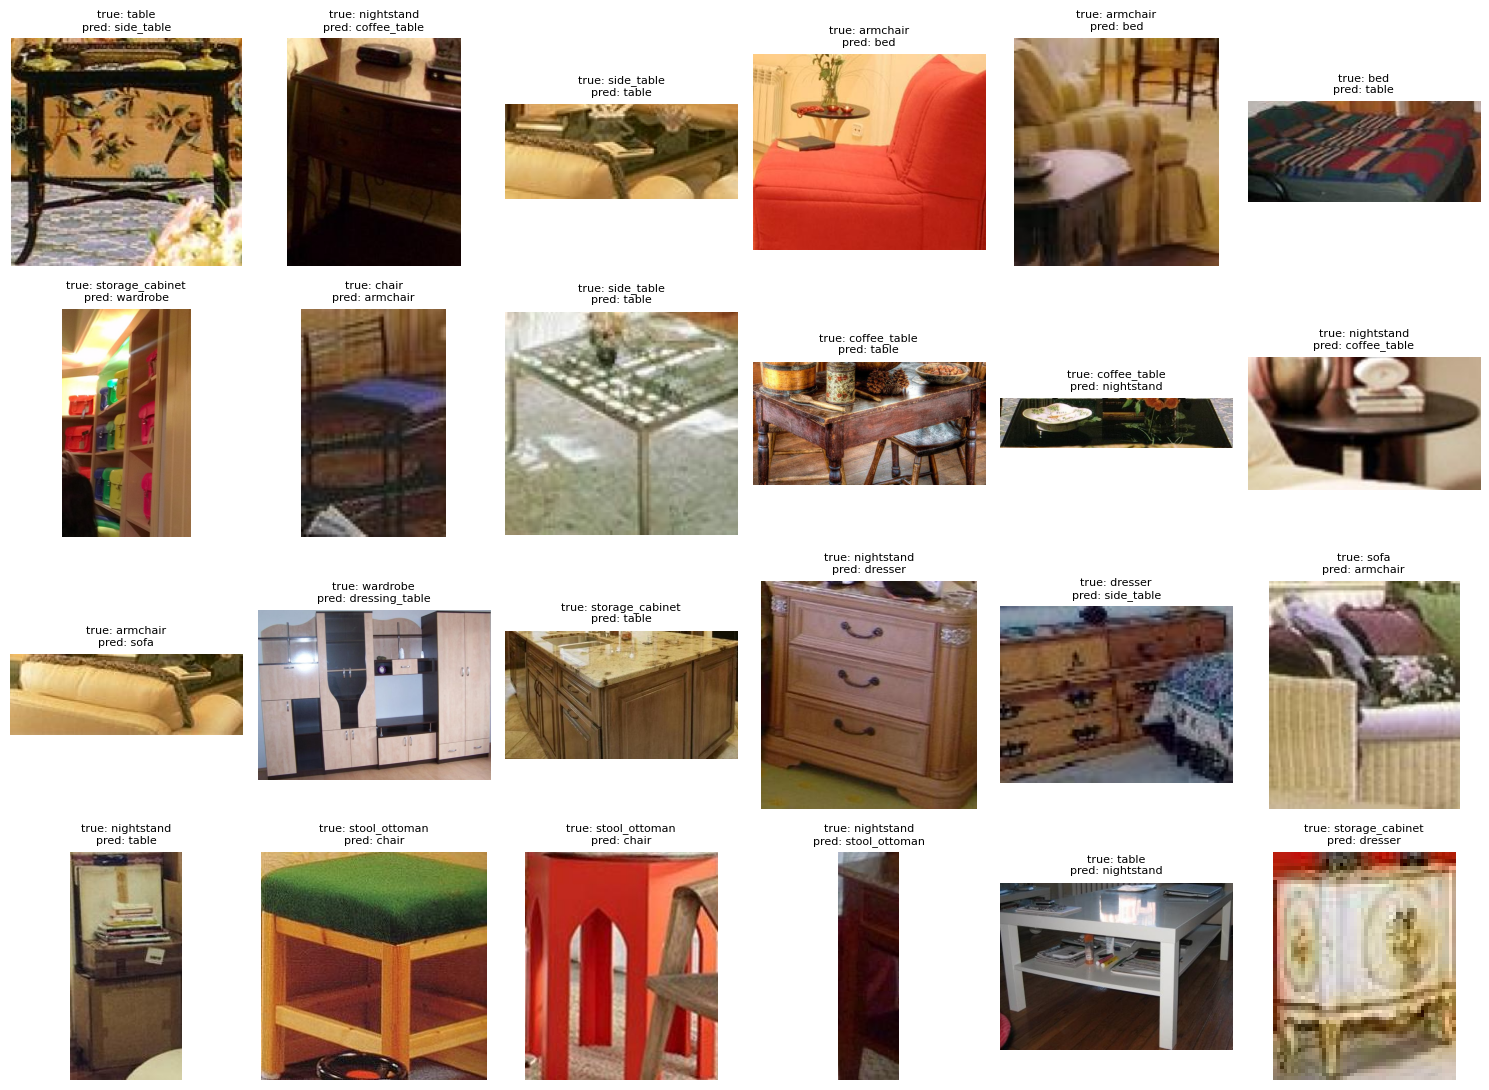

In [ ]:
# show wrong predictions on validation room crops, and the most common mix-ups
import pandas as pd
from pathlib import Path
from PIL import Image
man = pd.read_csv(f"{DRIVE}/furniture_v2_final_manifest.csv")
room = dict(zip(man["path"].map(lambda p: Path(p).name), man["room_crop"]))
paths = np.array([p for p, _ in val_ds.samples])
is_room = np.array([room[Path(p).name] for p in paths])

model.load_state_dict(torch.load(MODEL_PATH)); model.eval()
ys, ps = [], []
with torch.no_grad():
    for x, t in val_dl:
        ps.append(model(x.to(device)).argmax(1).cpu()); ys.append(t)
yv, pv = torch.cat(ys).numpy(), torch.cat(ps).numpy()

wrong = np.where(is_room & (yv != pv))[0]
print(len(wrong), "wrong room crops out of", is_room.sum())
print(pd.Series([f"{CLASSES[a]} → {CLASSES[b]}" for a, b in zip(yv[wrong], pv[wrong])]).value_counts().head(10))

pick = np.random.default_rng(0).choice(wrong, min(24, len(wrong)), replace=False)
fig, axes = plt.subplots(4, 6, figsize=(15, 11))
for ax, i in zip(axes.flat, pick):
    ax.imshow(Image.open(paths[i]).convert("RGB")); ax.axis("off")
    ax.set_title(f"true: {CLASSES[yv[i]]}\npred: {CLASSES[pv[i]]}", fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# are mistakes at least in the right family (seating, table, storage, bed)?
FAMILY = {"sofa": "seating", "armchair": "seating", "chair": "seating", "stool_ottoman": "seating",
          "table": "table", "coffee_table": "table", "side_table": "table", "desk": "table",
          "console_table": "table", "dressing_table": "table",
          "wardrobe": "storage", "dresser": "storage", "nightstand": "storage", "storage_cabinet": "storage",
          "bookshelf": "storage", "tv_stand": "storage", "bed": "bed"}
fam = np.array([FAMILY[c] for c in CLASSES])
print(f"{np.mean(fam[yv[wrong]] == fam[pv[wrong]]):.0%} of room-crop mistakes stay in the same family")
print(f"room-crop accuracy: exact class {np.mean(yv[is_room] == pv[is_room]):.2f} | family {np.mean(fam[yv[is_room]] == fam[pv[is_room]]):.2f}")

56% of room-crop mistakes stay in the same family
room-crop accuracy: exact class 0.54 | family 0.80


**Family accuracy:** on validation room crops, the exact class is right 54% of the time, but the furniture family (seating, table, storage, bed) is right 80% of the time. 56% of mistakes stay within the same family. The model recognises the kind of furniture well but struggles to separate close relatives in real room photos.

**Summary of Notebook 06:** Fine-tuning ResNet50 reached 0.622 val macro F1 (run 1) and 0.612 (run 2, with dropout and label smoothing). Both are no better than frozen ResNet50 features (0.64), and room crops stay weak (about 0.55 accuracy), mostly on look-alike classes like nightstand vs dresser and wardrobe vs storage_cabinet. Because training settings did not help, the next step compares other backbones (Notebook 07). The test set is not used here; it will be run once on the final model.